# 04 - Explainable AI for the frozen heart disease model

**MedIntel AI | Educational research prototype**

## 1. Introduction to Explainable AI

A classifier produces an output, but its output alone does not explain how it
used the inputs. SHAP assigns additive contributions relative to a chosen
background. We will explain the **existing fitted Logistic Regression** from
Phase 3, without retraining or changing its preprocessing, parameters, or threshold.

Objectives: inspect the exact transformed representation, explain all 61 held-out
records globally, inspect deterministic positive/negative/error examples, and
verify the mathematics. This notebook creates research explanations, not medical
diagnoses, causal conclusions, treatment advice, or validated clinical risk.

Dataset: Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989).
*Heart Disease* [Dataset]. UCI Machine Learning Repository.
[DOI](https://doi.org/10.24432/C52P4X),
[official dataset](https://archive.ics.uci.edu/dataset/45/heart+disease).
Cleveland data collection: Robert Detrano, Cleveland Clinic Foundation;
UCI lists the dataset under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

Run from the project root or `notebooks/` using the virtual environment after
installing `requirements.txt`. All steps run independently of earlier kernels.

## 2. Why explainability matters in healthcare research

Explanations can expose unexpected reliance on an encoded variable, help audit
mistakes, and communicate what a particular model did. They cannot establish
that a feature causes disease or that a prediction is clinically valid.
Important inputs may be diagnostic tests unavailable at an earlier decision time.

**Code explanation:** Locate the existing project and import the reusable XAI
functions. NumPy supports consistency checks; pandas and Jupyter display the
tables and figures. Print SHAP's actual installed version. No estimator is
fitted, and no variables from previous notebooks are required.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys

import numpy as np
import pandas as pd
from scipy.special import expit
import shap
from IPython.display import Image, Markdown, display

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(folder for folder in [cwd, *cwd.parents]
                    if (folder / "src/explainability.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_heart_data, split_data
from src.explainability import (
    build_explainer, explain_global, explain_individual, feature_mapping,
    global_importance, group_contributions, load_explanation_model,
    run_explainability, transform_records, validate_reconstruction,
)
from src.train import load_experiment_report

print("SHAP:", shap.__version__)
print("Project:", PROJECT_ROOT)

SHAP: 0.54.1
Project: C:\MedIntel-AI


## 3. Load and verify the saved model

**Code explanation:** Load the trusted local pipeline only after checking the
Phase 3 manifest and artifact fingerprint. Joblib can execute code; explicit
trust applies only to this artifact that the project created. Confirm the fitted
preprocessor and Logistic Regression and record the artifact's hash for the final
preservation check. This loads the existing model; it never replaces or retrains it.

The displayed Phase 3 metrics are recorded results, not a new evaluation.

In [2]:
training_report = load_experiment_report(PROJECT_ROOT)
pipeline = load_explanation_model(PROJECT_ROOT, trusted=True)
artifact_path = PROJECT_ROOT / training_report["artifact"]
artifact_before = sha256(artifact_path.read_bytes()).hexdigest()
print("Steps:", list(pipeline.named_steps))
print("Classifier:", type(pipeline.named_steps["classifier"]).__name__)
print("Verified artifact SHA-256:", artifact_before)
display(pd.Series(training_report["evaluation"]["metrics"], name="Saved Phase 3 metric").to_frame().round(4))

Steps: ['preprocessor', 'classifier']
Classifier: LogisticRegression
Verified artifact SHA-256: 82ebbcac02ce7dafd841f1f44d477b758ad05124f7f2b767b9fc8bae07546f4a


,Saved Phase 3 metric
accuracy,0.8689
precision,0.8125
recall,0.9286
f1,0.8667
roc_auc,0.9665
sensitivity,0.9286
specificity,0.8182
brier_score,0.0832


## 4. Reconstruct the unchanged data split

**Code explanation:** The loader verifies the original UCI snapshot and creates
the same binary target. The seed-42 stratified split produces 242 training and
61 test records. Assert no overlap. Training rows are the **only** explanation
background; test rows are explained after the model is frozen. Test labels are
used only to describe an educational error, never for fitting or changing the model.

In [3]:
X, y = load_heart_data(PROJECT_ROOT / "data/raw/processed.cleveland.data")
X_train, X_test, y_train, y_test = split_data(X, y)
assert X_train.index.intersection(X_test.index).empty
print(f"Training background: {len(X_train)} records; held-out explanations: {len(X_test)} records.")
print("Target: original num=0 -> absence; num=1-4 -> recorded presence.")

Training background: 242 records; held-out explanations: 61 records.
Target: original num=0 -> absence; num=1-4 -> recorded presence.


## 5. Understand the 28 transformed features

**Code explanation:** Extract output names directly from the fitted transformer
and align them with coefficients, branch metadata, and each encoder category.
No hardcoded column positions or string-prefix guesses determine ownership.
The table maps all 28 outputs to the 13 original variables.

Numeric measurements are standardized using frozen training statistics.
One-hot values are indicators, not continuous category codes: for example,
`cp_4.0=1` means the original chest-pain code is 4. A value of 0 can also have
a SHAP contribution because its training-background mean is generally not zero.
A coefficient describes log-odds change per transformed unit; its sign is not a
causal effect. Full one-hot coding and correlations complicate comparisons.

In [4]:
mapping = feature_mapping(pipeline)
classifier = pipeline.named_steps["classifier"]
assert len(mapping) == classifier.coef_.shape[1] == 28
coefficient_table = mapping.copy()
coefficient_table["coefficient_log_odds"] = classifier.coef_[0]
display(coefficient_table)
print("Intercept (log-odds):", float(classifier.intercept_[0]))

,transformed_feature,original_feature,representation,category,coefficient_log_odds
0,numeric__age,age,standardized_measurement,NaN,-0.055559
1,numeric__trestbps,trestbps,standardized_measurement,NaN,0.342684
2,numeric__chol,chol,standardized_measurement,NaN,0.187081
3,numeric__thalach,thalach,standardized_measurement,NaN,-0.389549
4,numeric__oldpeak,oldpeak,standardized_measurement,NaN,0.246491
5,categorical__sex_0.0,sex,one_hot_indicator,0.0,-0.698358
6,categorical__sex_1.0,sex,one_hot_indicator,1.0,0.711635
7,categorical__cp_1.0,cp,one_hot_indicator,1.0,-0.592738
8,categorical__cp_2.0,cp,one_hot_indicator,2.0,0.142882
9,categorical__cp_3.0,cp,one_hot_indicator,3.0,-0.572025


Intercept (log-odds): 0.03619388061994067


## 6. Create a training-background SHAP explainer

We use [LinearExplainer](https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html)
with [Independent masking](https://shap.readthedocs.io/en/latest/generated/shap.maskers.Independent.html)
in transformed space. Every one of the 242 training records is retained by
explicitly setting `max_samples` to 242, rather than accepting the masker's
default subsampling limit. No sampling or model/preprocessing fit is needed.

For transformed input z, this binary linear model has log-odds
`intercept + coefficient dot z`. Under independent masking, a feature's SHAP
contribution is its coefficient times its deviation from the background mean.
The baseline is the mean **log-odds**, including the intercept, on that background.
It is not simply the intercept and is not a probability.

Independent masking does not respect correlations or mutual exclusivity between
dummy columns. The attribution allocation is conditional on that modeling
convention; it is not an intervention on a real patient or a causal result.

**Code explanation:** Build the explanation context and display the baseline
and background size. We keep the existing fitted transformer unchanged.

In [5]:
engine = build_explainer(pipeline, X_train)
assert engine.background_records == 242
baseline_log_odds = float(np.asarray(engine.explainer.expected_value))
print("Background rows:", engine.background_records)
print("Baseline log-odds:", baseline_log_odds)
print("Sigmoid of baseline:", float(expit(baseline_log_odds)))
print("Sigmoid of mean log-odds is not the mean model score or a clinical prevalence estimate.")

Background rows: 242
Baseline log-odds: 0.008865224204336043
Sigmoid of baseline: 0.502216291535834
Sigmoid of mean log-odds is not the mean model score or a clinical prevalence estimate.


## 7. Calculate global SHAP importance

**Code explanation:** Explain all 61 test rows using the fixed background and
calculate each transformed feature's mean absolute contribution. Larger values
mean more model influence in this explained sample; they do not imply clinical
relevance or causality. The function returns actual SHAP calculations in log-odds.

`run_explainability` exports figures and non-identifying summary metadata, or
validates an existing completed Phase 4 run. Its provenance checks preserve
the model, source, and Phase 3 report. The displayed table ranks the actual top
ten transformed features; no feature is assumed important in advance.

,transformed_feature,original_feature,representation,category,mean_absolute_shap,mean_signed_shap
0,categorical__ca_0.0,ca,one_hot_indicator,0.0,0.735965,0.129449
1,categorical__cp_4.0,cp,one_hot_indicator,4.0,0.515616,-0.042284
2,categorical__thal_7.0,thal,one_hot_indicator,7.0,0.388427,-0.026365
3,numeric__thalach,thalach,standardized_measurement,NaN,0.330039,0.030388
4,categorical__sex_1.0,sex,one_hot_indicator,1.0,0.311274,-0.006894
5,categorical__sex_0.0,sex,one_hot_indicator,0.0,0.305466,-0.006765
6,categorical__slope_2.0,slope,one_hot_indicator,2.0,0.301654,0.022511
7,categorical__thal_3.0,thal,one_hot_indicator,3.0,0.259655,0.019538
8,categorical__cp_3.0,cp,one_hot_indicator,3.0,0.248464,-0.055025
9,numeric__oldpeak,oldpeak,standardized_measurement,NaN,0.243756,0.044174


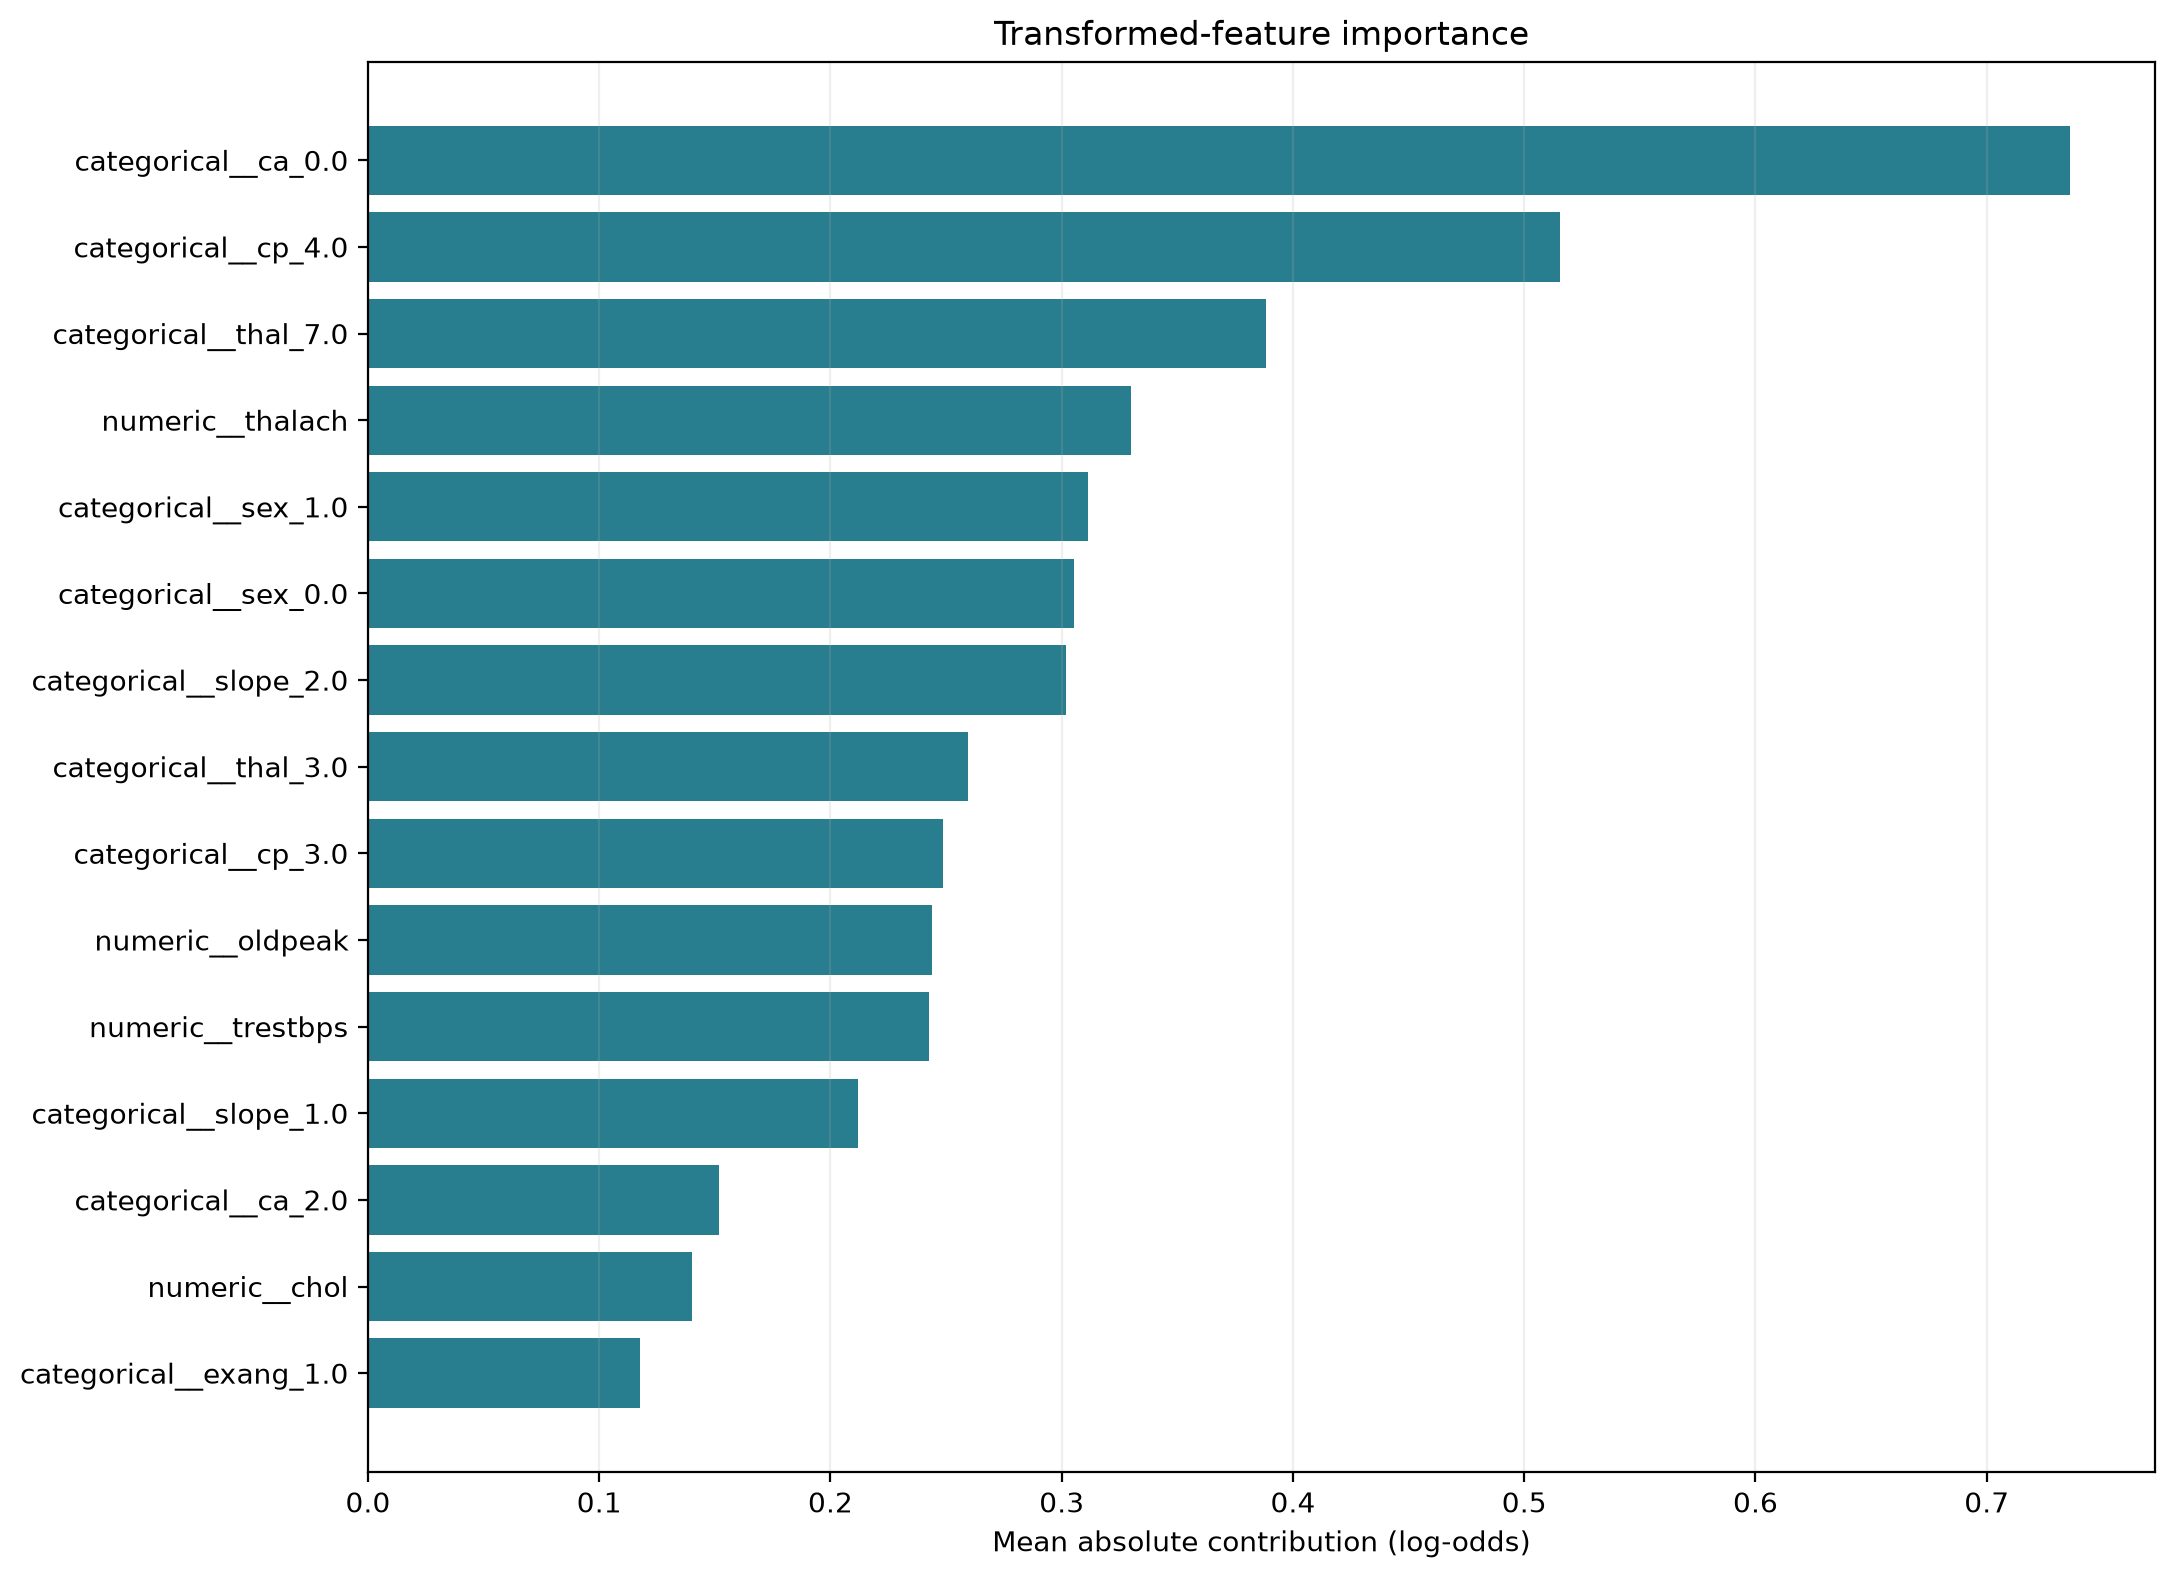

In [6]:
shap_values = explain_global(engine, X_test)
transformed_importance, grouped_importance = global_importance(shap_values, mapping)
report = run_explainability(PROJECT_ROOT)
np.testing.assert_allclose(
    transformed_importance["mean_absolute_shap"],
    [row["mean_absolute_shap"] for row in report["global_transformed_importance"]],
)
display(transformed_importance.head(10))
display(Image(filename=str(PROJECT_ROOT / "reports/figures/explainability/global_mean_absolute_shap.png")))

## 8. Read the SHAP beeswarm

**Code explanation:** Display the exported [beeswarm](https://shap.readthedocs.io/en/latest/generated/shap.plots.beeswarm.html).
Each dot is one record's contribution for a transformed feature; the remaining
less prominent features are combined in the last displayed row. Positive
horizontal positions increase positive-class log-odds relative to the baseline;
negative positions decrease them. Through the sigmoid, this also changes the
model score in the same direction, but contribution magnitudes are not probability
points. Color shows transformed values: scaled measurements or 0/1 indicators.
For dummy columns, a high value means that category indicator is active, not a
greater amount of disease. Vertical jitter separates overlapping dots and is
seeded for repeatable plotting; it has no medical meaning.

The combined remaining-features row has no single original-variable color interpretation.

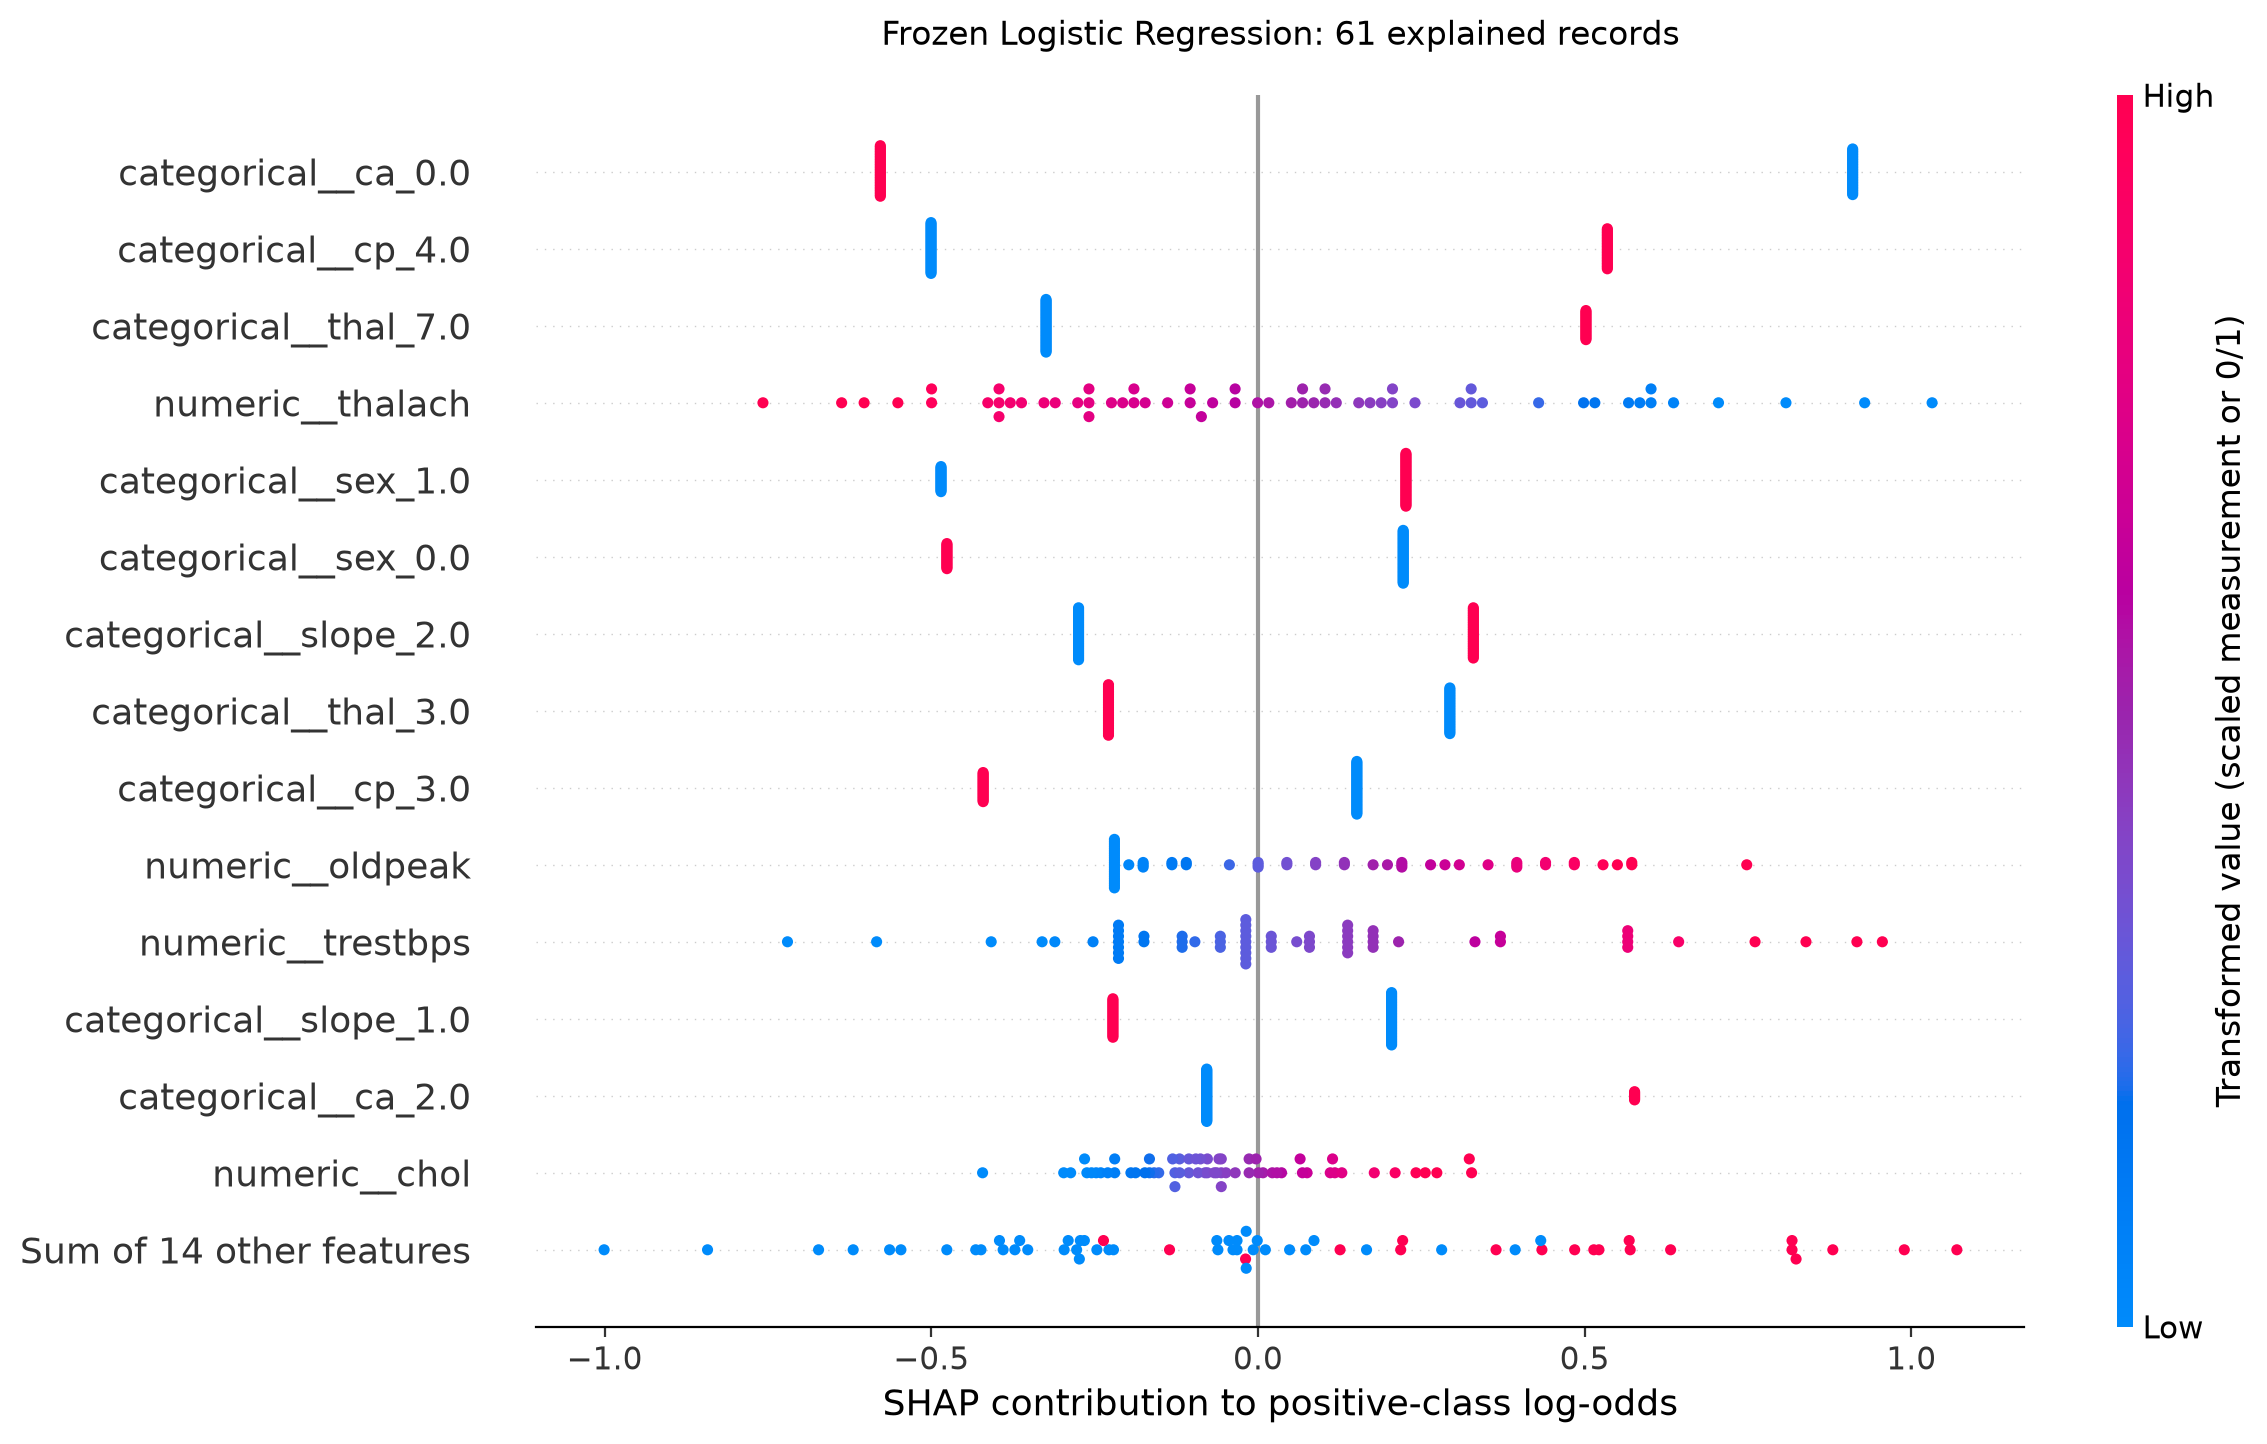

In [7]:
display(Image(filename=str(PROJECT_ROOT / "reports/figures/explainability/shap_beeswarm.png")))

## 9. Group encoded features by original variable

**Code explanation:** Sum signed dummy contributions per record to obtain net
contributions for each original variable, and verify that additive totals are
preserved. The importance chart instead uses the **sum of mean absolute encoded
contributions**, avoiding cancellation within a group. The adjacent table also
reports `mean_absolute_net_shap`, which can be smaller because opposite-signed
dummy contributions cancel before taking the absolute value.

These are summaries of the existing transformed-feature SHAP values, not a
new group-coalition SHAP calculation. Variables with more dummy columns have
more terms in the magnitude-sum metric. Ranking can change with representation,
background, and evaluation sample. Inspect the measured results for age,
chest pain, cholesterol, blood pressure, heart rate, and exercise angina rather
than assuming those examples must rank highest.

,original_feature,sum_mean_absolute_shap,mean_absolute_net_shap
0,ca,1.086024,0.975172
1,cp,0.880414,0.722195
2,thal,0.691603,0.610354
3,sex,0.616741,0.616741
4,slope,0.536191,0.493408
5,thalach,0.330039,0.330039
6,oldpeak,0.243756,0.243756
7,trestbps,0.242444,0.242444
8,exang,0.229511,0.229511
9,restecg,0.182330,0.175156


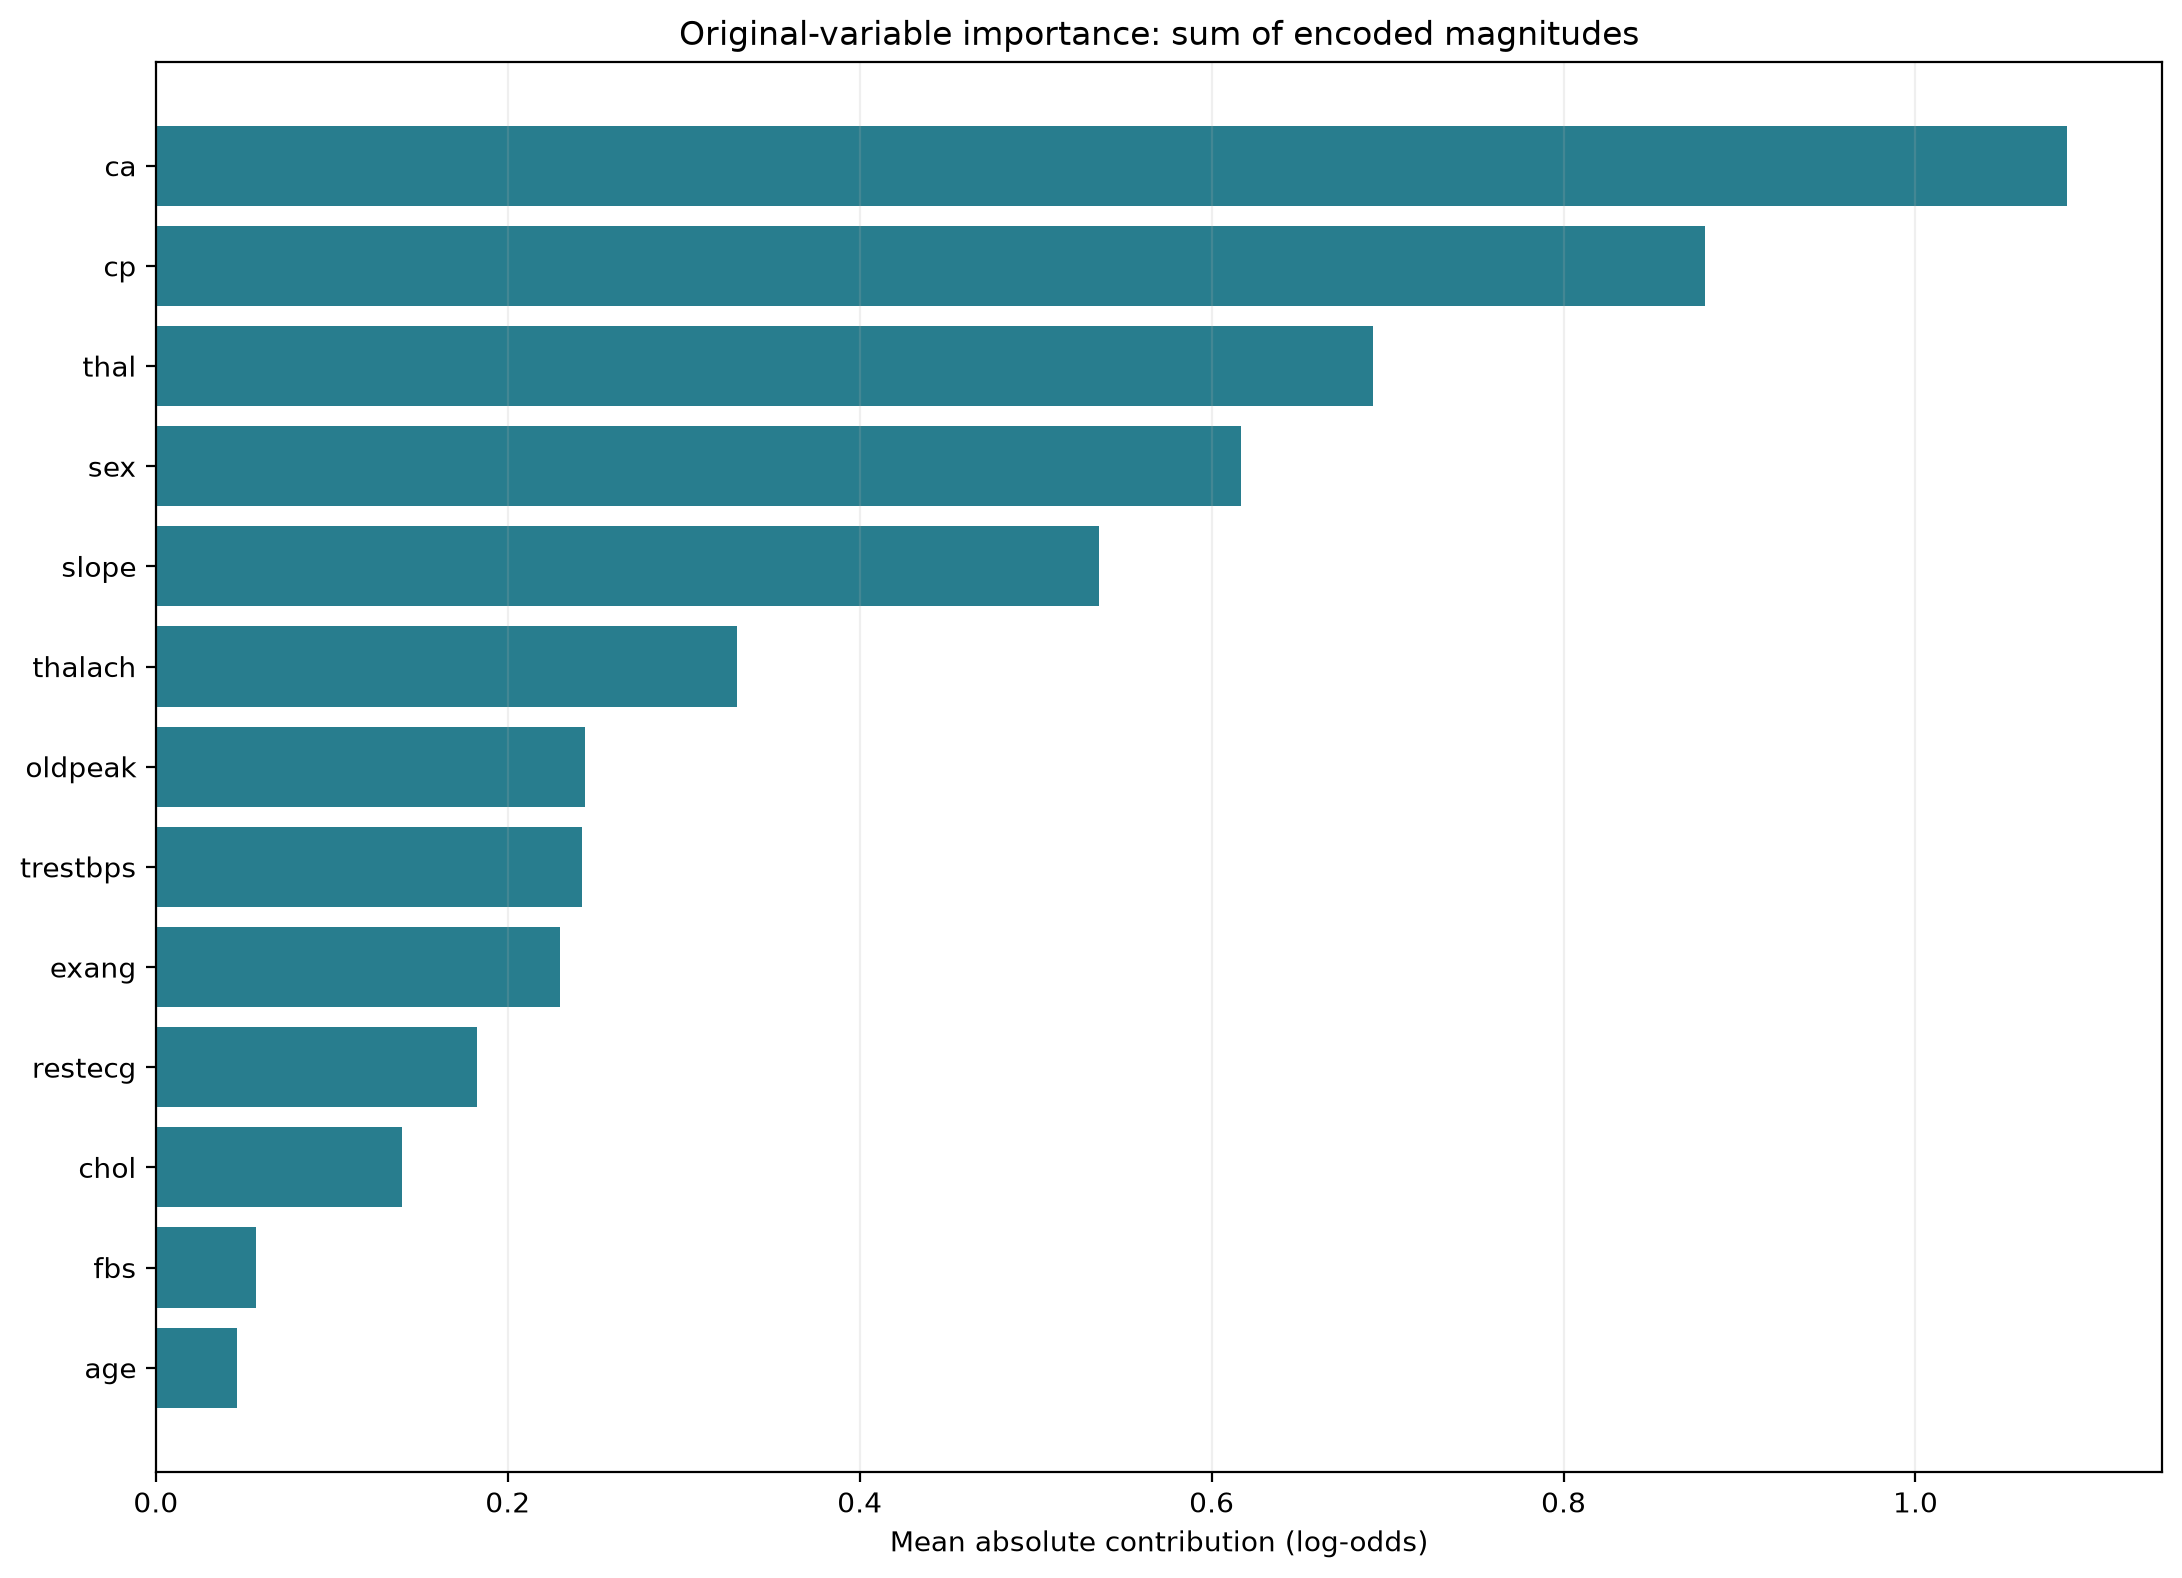

,sum_mean_absolute_shap,mean_absolute_net_shap
original_feature,,
age,0.046183,0.046183
cp,0.880414,0.722195
chol,0.140110,0.140110
trestbps,0.242444,0.242444
thalach,0.330039,0.330039
exang,0.229511,0.229511


In [8]:
grouped_signed = group_contributions(shap_values, mapping)
np.testing.assert_allclose(grouped_signed.sum(axis=1), shap_values.values.sum(axis=1), atol=1e-10)
display(grouped_importance)
display(Image(filename=str(PROJECT_ROOT / "reports/figures/explainability/grouped_original_importance.png")))
display(grouped_importance.set_index("original_feature").loc[["age", "cp", "chol", "trestbps", "thalach", "exang"]])

## 10. Individual explanation: predicted presence

**Code explanation:** Select the first held-out position predicted as present
in the existing split order. The helper below only renders examples using the
exported summary and SHAP functions. The displayed input is a public UCI research
record, with its original row index removed, not a patient-identifying profile.
Missing input cells are displayed as missing; the fitted imputer handles them.

The output includes recorded versus predicted class, the uncalibrated score,
and the strongest positive/negative transformed contributions. The waterfall
starts at the training-background baseline and adds log-odds contributions to
reach this model's output. Positive contributions push toward recorded-presence
class 1; negative ones oppose that direction. The final score is a model output,
not a clinically calibrated probability or a diagnosis.

Example: positive; zero-based holdout position 1.


,Public UCI example value
age,66.0
sex,1.0
cp,4.0
trestbps,160.0
chol,228.0
fbs,0.0
restecg,2.0
thalach,138.0
exang,0.0
oldpeak,2.3


,Value
predicted_class,1.000000
recorded_class,0.000000
model_score,0.638220
baseline_log_odds,0.008865
sum_shap_log_odds,0.558781
reconstructed_log_odds,0.567646


,direction,feature,contribution_log_odds
0,positive,numeric__trestbps,0.565901
1,positive,categorical__cp_4.0,0.534689
2,positive,categorical__thal_3.0,0.293634
3,negative,categorical__ca_0.0,-0.578085
4,negative,categorical__thal_7.0,-0.324389
5,negative,categorical__thal_6.0,-0.277357


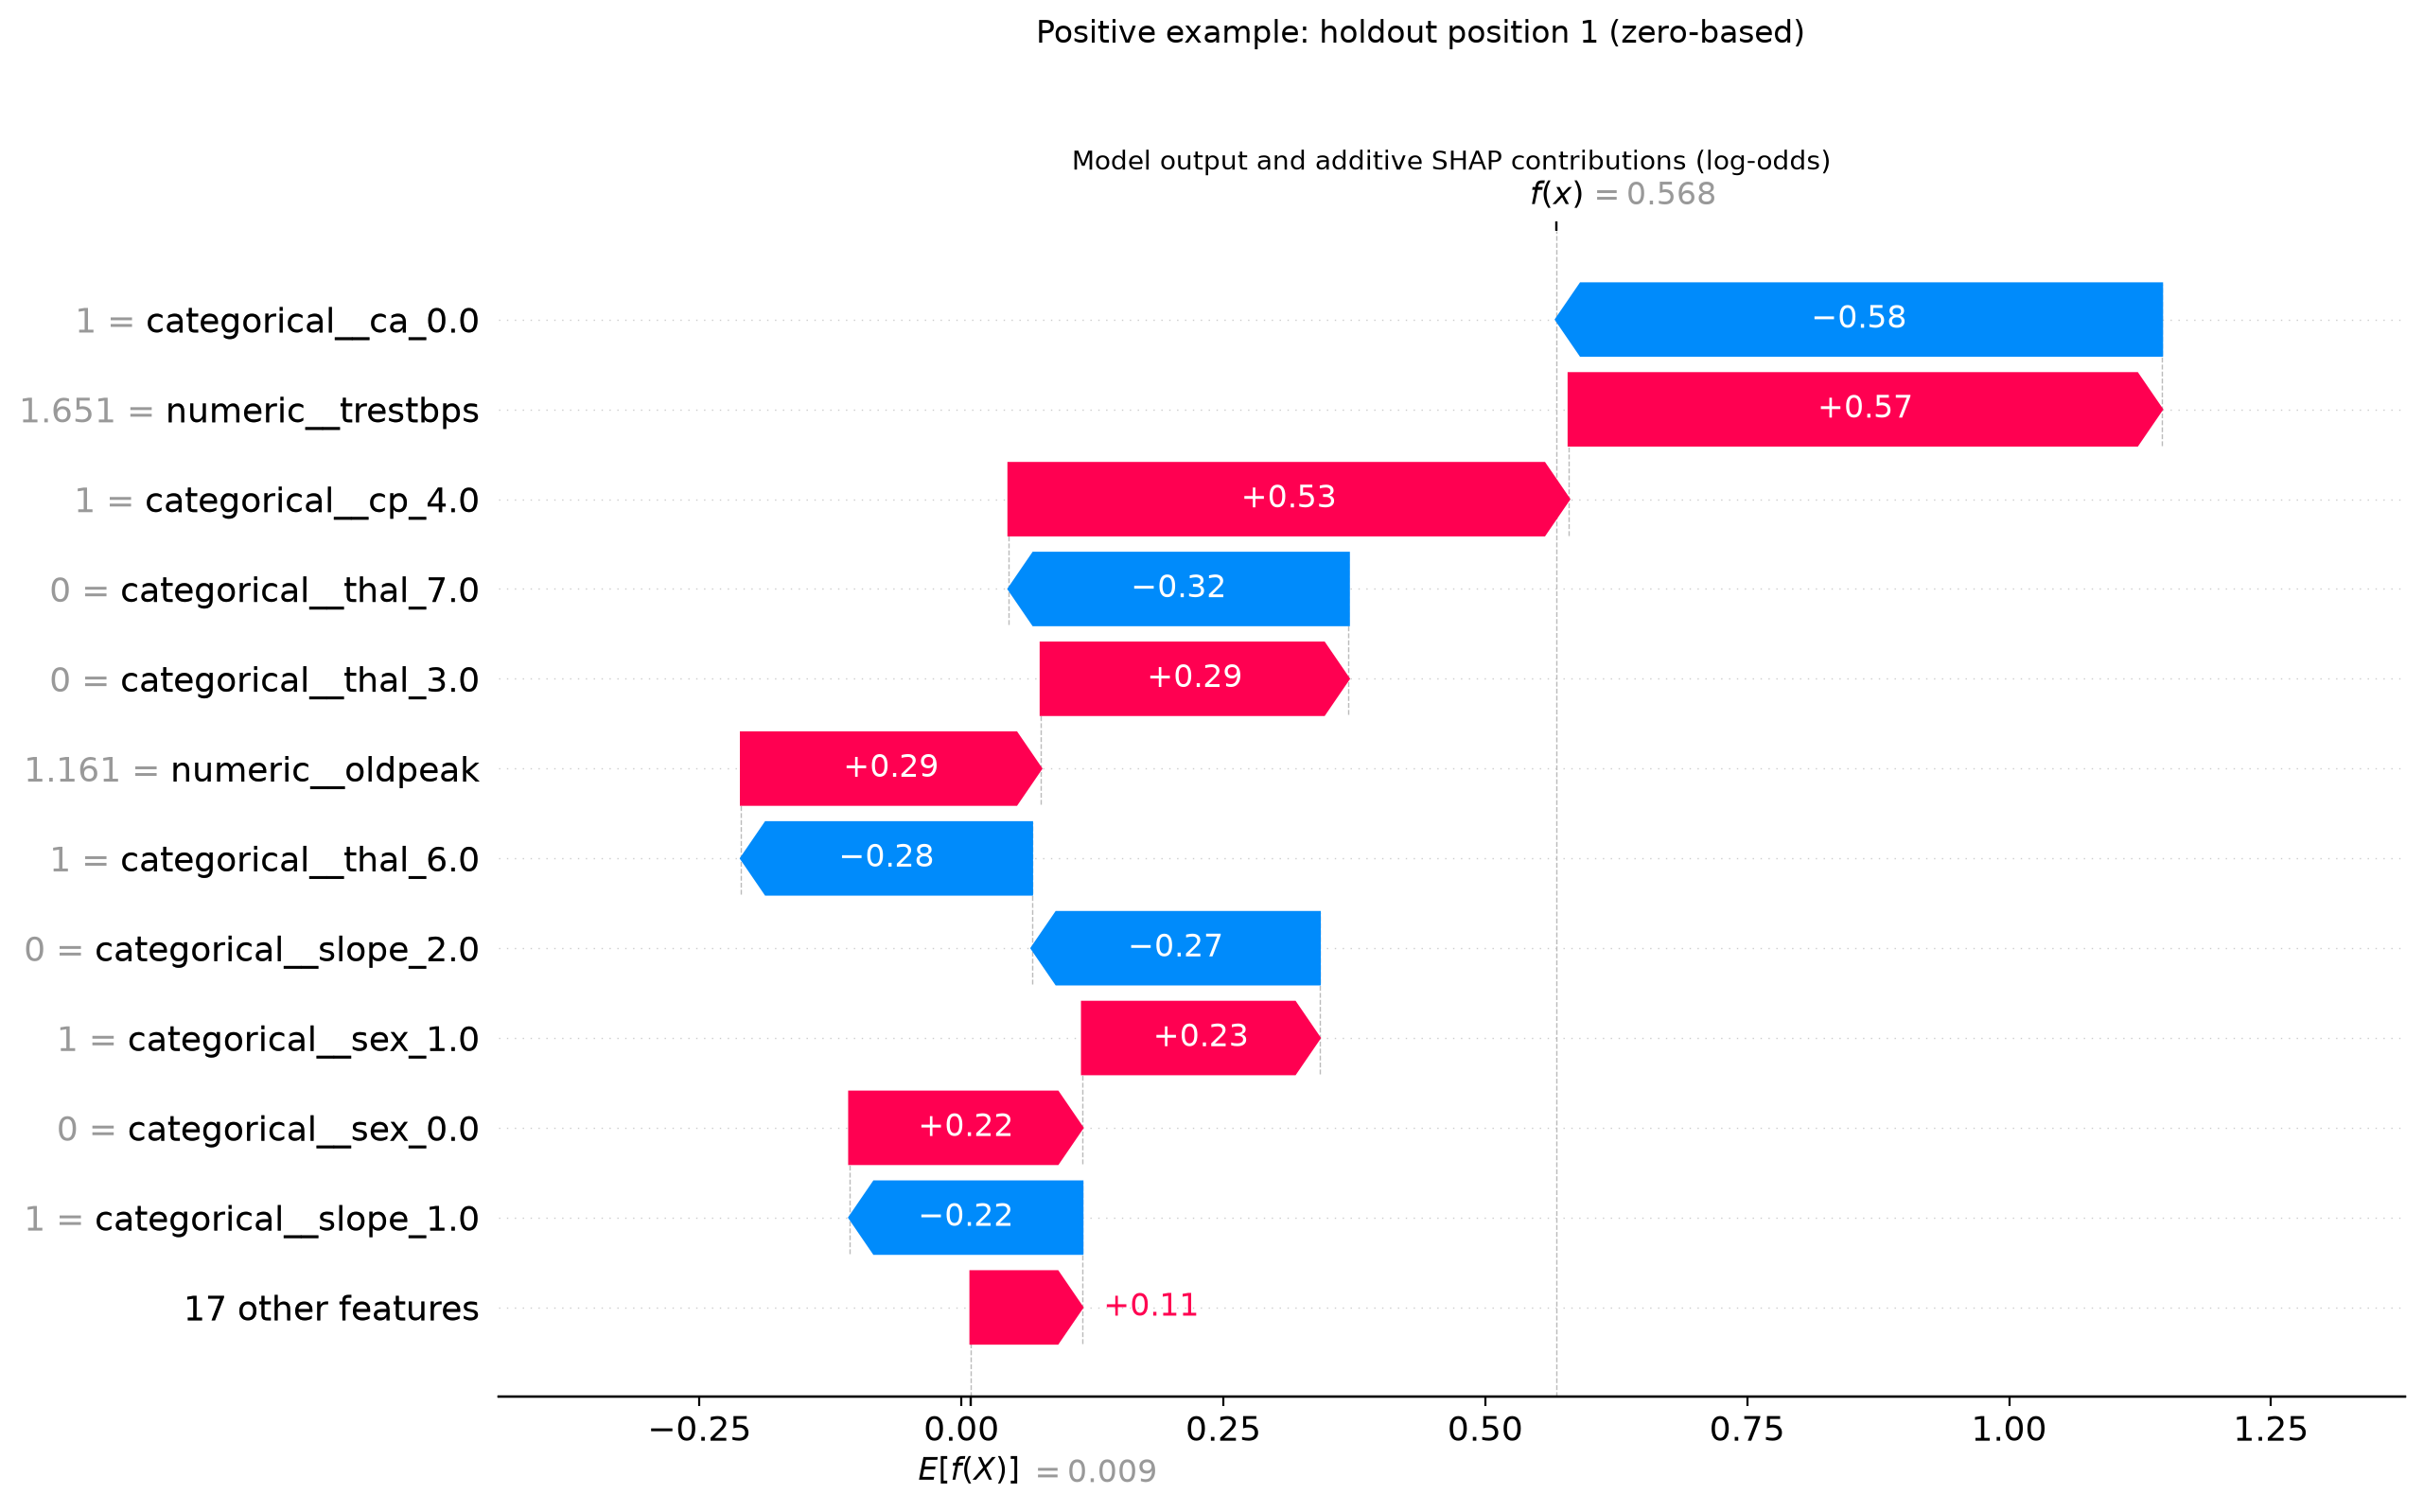

The largest upward contribution is **numeric__trestbps**; the largest downward contribution is **categorical__ca_0.0**. Their signs describe this model relative to its background, not medical causes.

In [9]:
def display_example(name):
    if name not in report["examples"]:
        print(f"No {name} example exists in this explained set.")
        return
    summary = report["examples"][name]
    position = summary["holdout_position"]
    record = X_test.iloc[[position]]
    local = explain_individual(engine, record)
    np.testing.assert_allclose(local.values, shap_values.values[position], atol=1e-12)
    print(f"Example: {name}; zero-based holdout position {position}.")
    display(record.reset_index(drop=True).T.rename(columns={0: "Public UCI example value"}))
    display(pd.Series({key: summary[key] for key in ["predicted_class", "recorded_class", "model_score", "baseline_log_odds", "sum_shap_log_odds", "reconstructed_log_odds"]}).to_frame("Value"))
    contributions = [{"direction": direction, **row}
                     for direction, rows in summary["strongest_contributions"].items() for row in rows]
    display(pd.DataFrame(contributions))
    display(Image(filename=str(PROJECT_ROOT / "reports/figures/explainability" / f"waterfall_{name}.png")))
    up = summary["strongest_contributions"]["positive"]
    down = summary["strongest_contributions"]["negative"]
    display(Markdown(f"The largest upward contribution is **{up[0]['feature'] if up else 'none'}**; "
                     f"the largest downward contribution is **{down[0]['feature'] if down else 'none'}**. "
                     "Their signs describe this model relative to its background, not medical causes."))

display_example("positive")

## 11. Individual explanation: predicted absence

**Code explanation:** Render the first held-out position predicted as absent,
using the same deterministic rule and background. A negative final log-odds
gives a score below 0.5. Negative contributions may outweigh positive ones;
that describes this classifier's behavior and does not rule out disease.
Compare the two examples' inputs and contributions without making medical advice.

Example: negative; zero-based holdout position 0.


,Public UCI example value
age,59.0
sex,1.0
cp,4.0
trestbps,138.0
chol,271.0
fbs,0.0
restecg,2.0
thalach,182.0
exang,0.0
oldpeak,0.0


,Value
predicted_class,0.000000
recorded_class,0.000000
model_score,0.238645
baseline_log_odds,0.008865
sum_shap_log_odds,-1.168987
reconstructed_log_odds,-1.160122


,direction,feature,contribution_log_odds
0,positive,categorical__cp_4.0,0.534689
1,positive,categorical__sex_1.0,0.226429
2,positive,categorical__sex_0.0,0.222205
3,negative,categorical__ca_0.0,-0.578085
4,negative,numeric__thalach,-0.551251
5,negative,categorical__thal_7.0,-0.324389


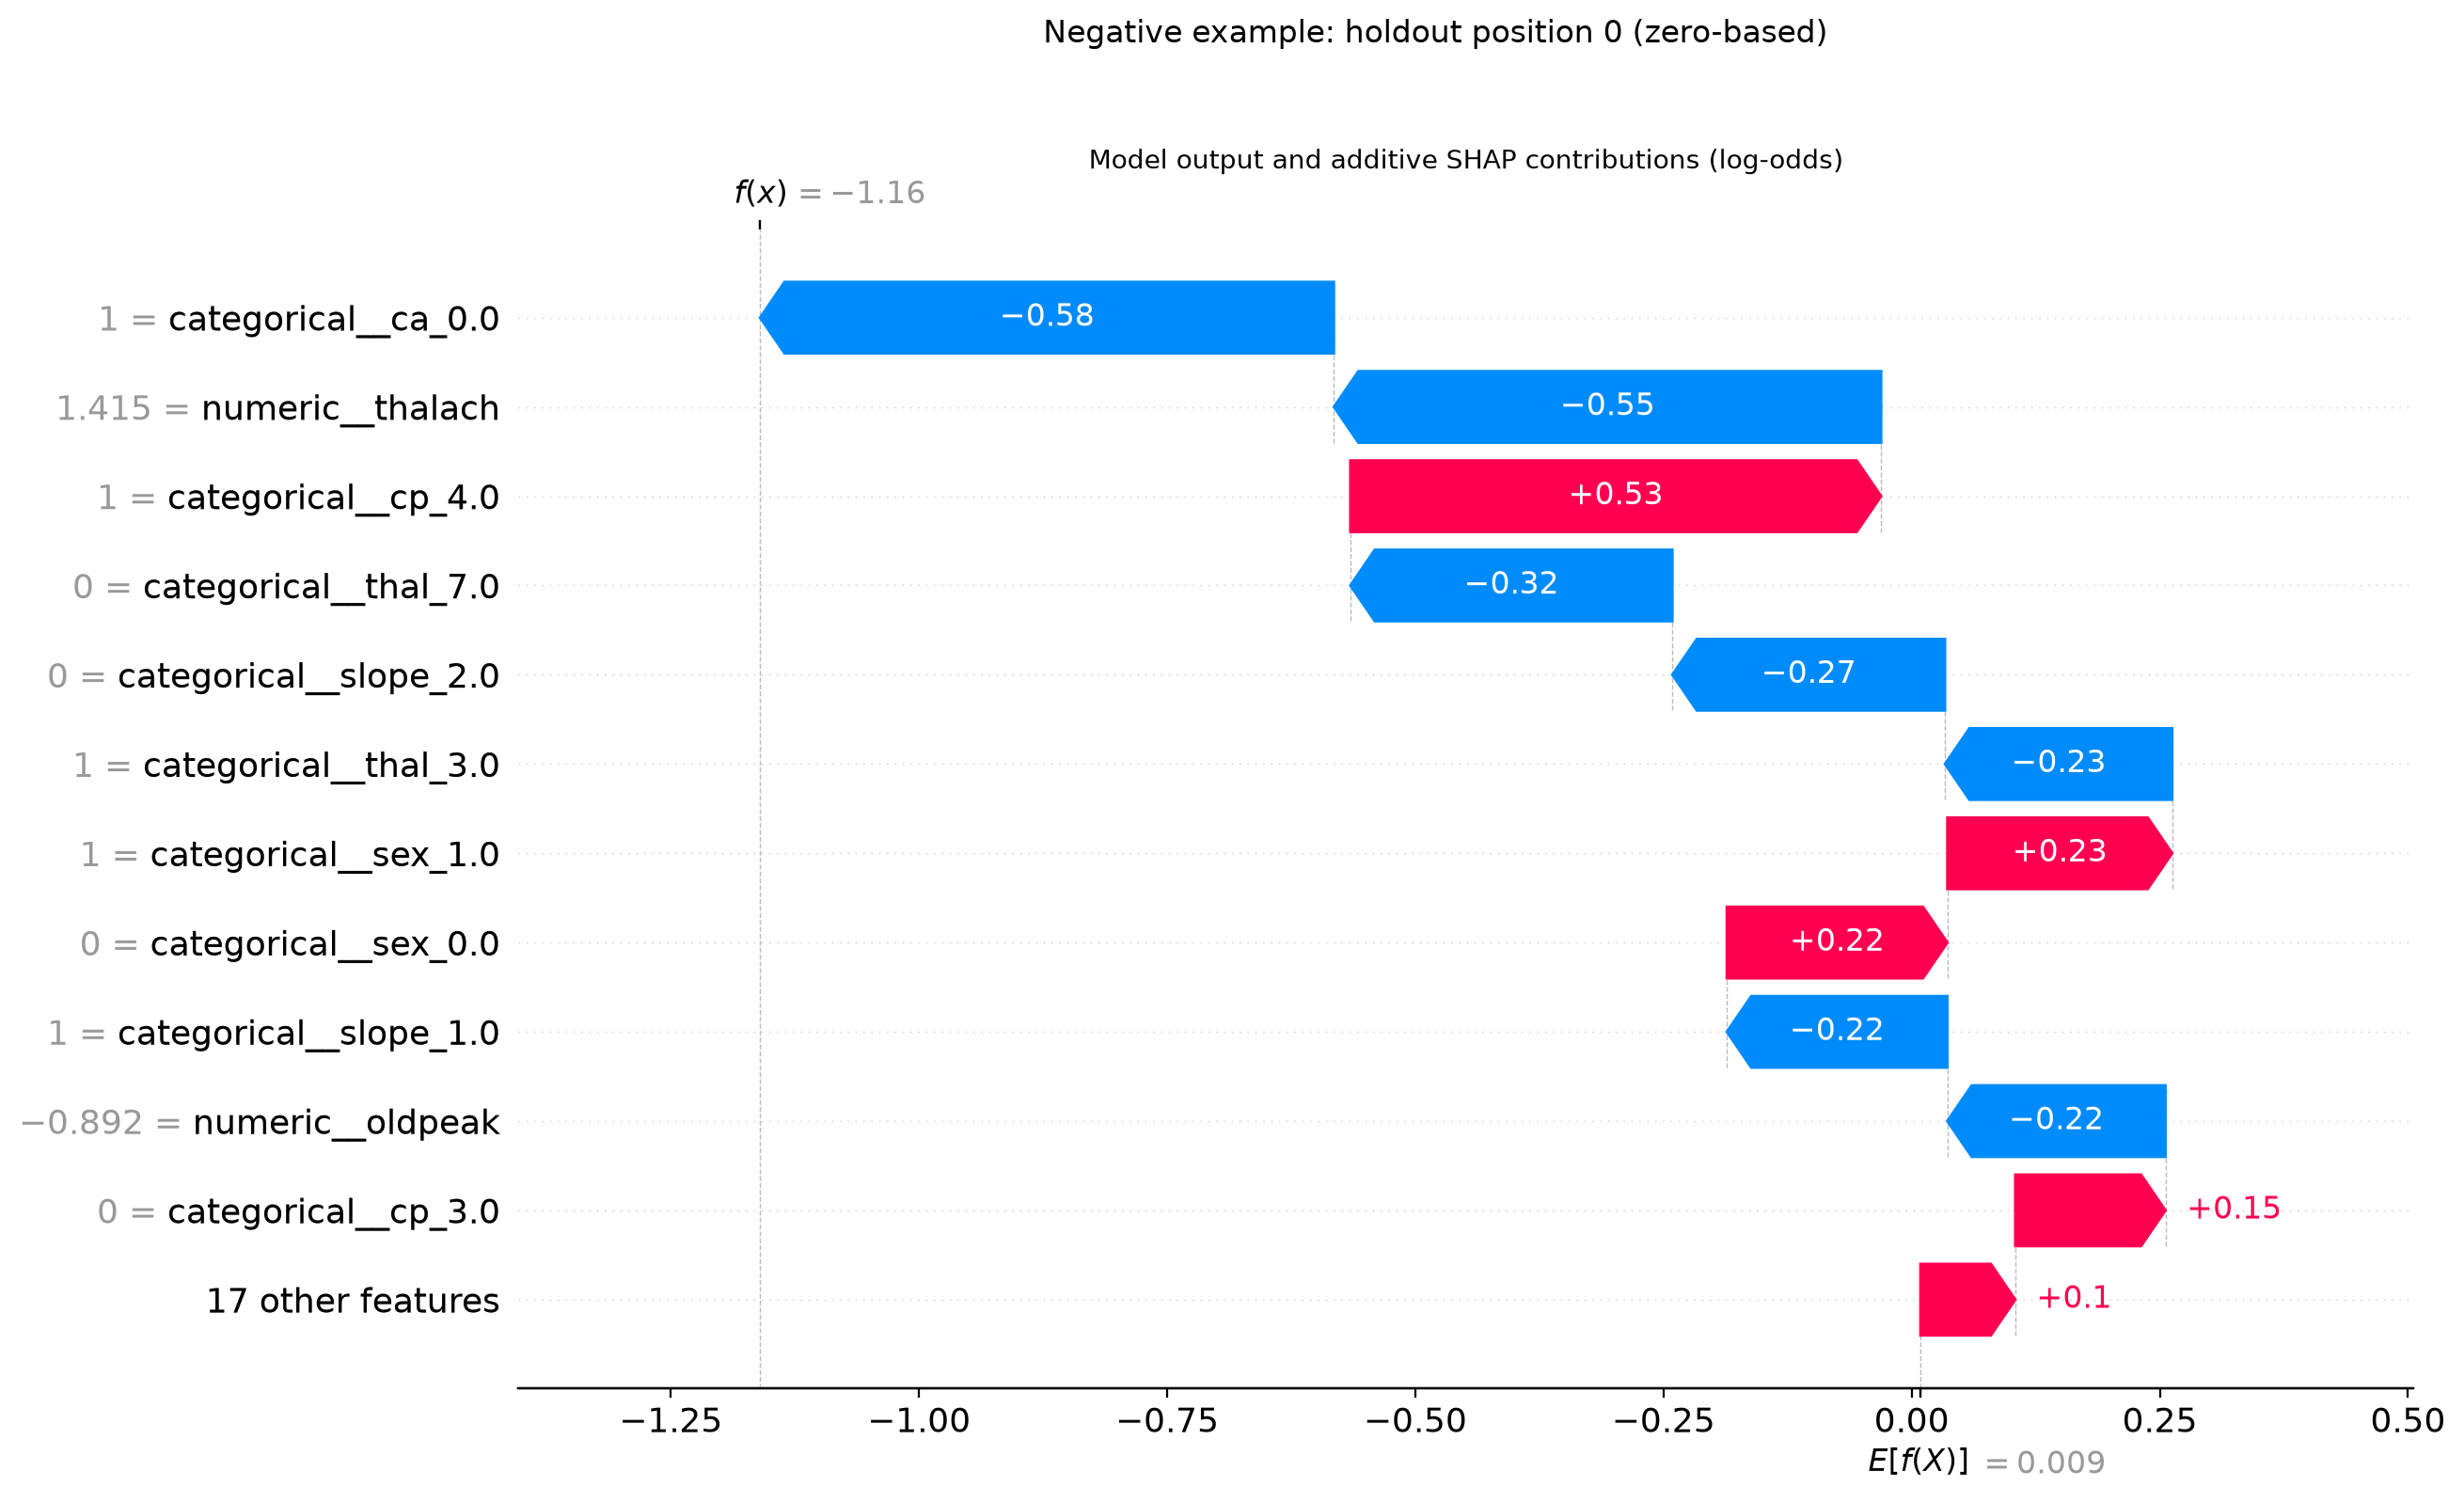

The largest upward contribution is **categorical__cp_4.0**; the largest downward contribution is **categorical__ca_0.0**. Their signs describe this model relative to its background, not medical causes.

In [10]:
display_example("negative")

## 12. Educational misclassification analysis

**Code explanation:** Show the first disagreement not already selected for the
positive/negative examples, if available; otherwise use the first disagreement. Label access only identifies an error for
inspection; it does not change the selected examples' scores, the background,
threshold, or model. A coherent additive explanation can accompany a wrong
classification. Explainability does not prove correctness.

Example: misclassified; zero-based holdout position 17.


,Public UCI example value
age,69.0
sex,1.0
cp,1.0
trestbps,160.0
chol,234.0
fbs,1.0
restecg,2.0
thalach,131.0
exang,0.0
oldpeak,0.1


,Value
predicted_class,1.000000
recorded_class,0.000000
model_score,0.730097
baseline_log_odds,0.008865
sum_shap_log_odds,0.986250
reconstructed_log_odds,0.995115


,direction,feature,contribution_log_odds
0,positive,categorical__ca_0.0,0.910177
1,positive,numeric__trestbps,0.565901
2,positive,categorical__slope_2.0,0.329568
3,negative,categorical__cp_1.0,-0.546201
4,negative,categorical__cp_4.0,-0.500469
5,negative,categorical__thal_7.0,-0.324389


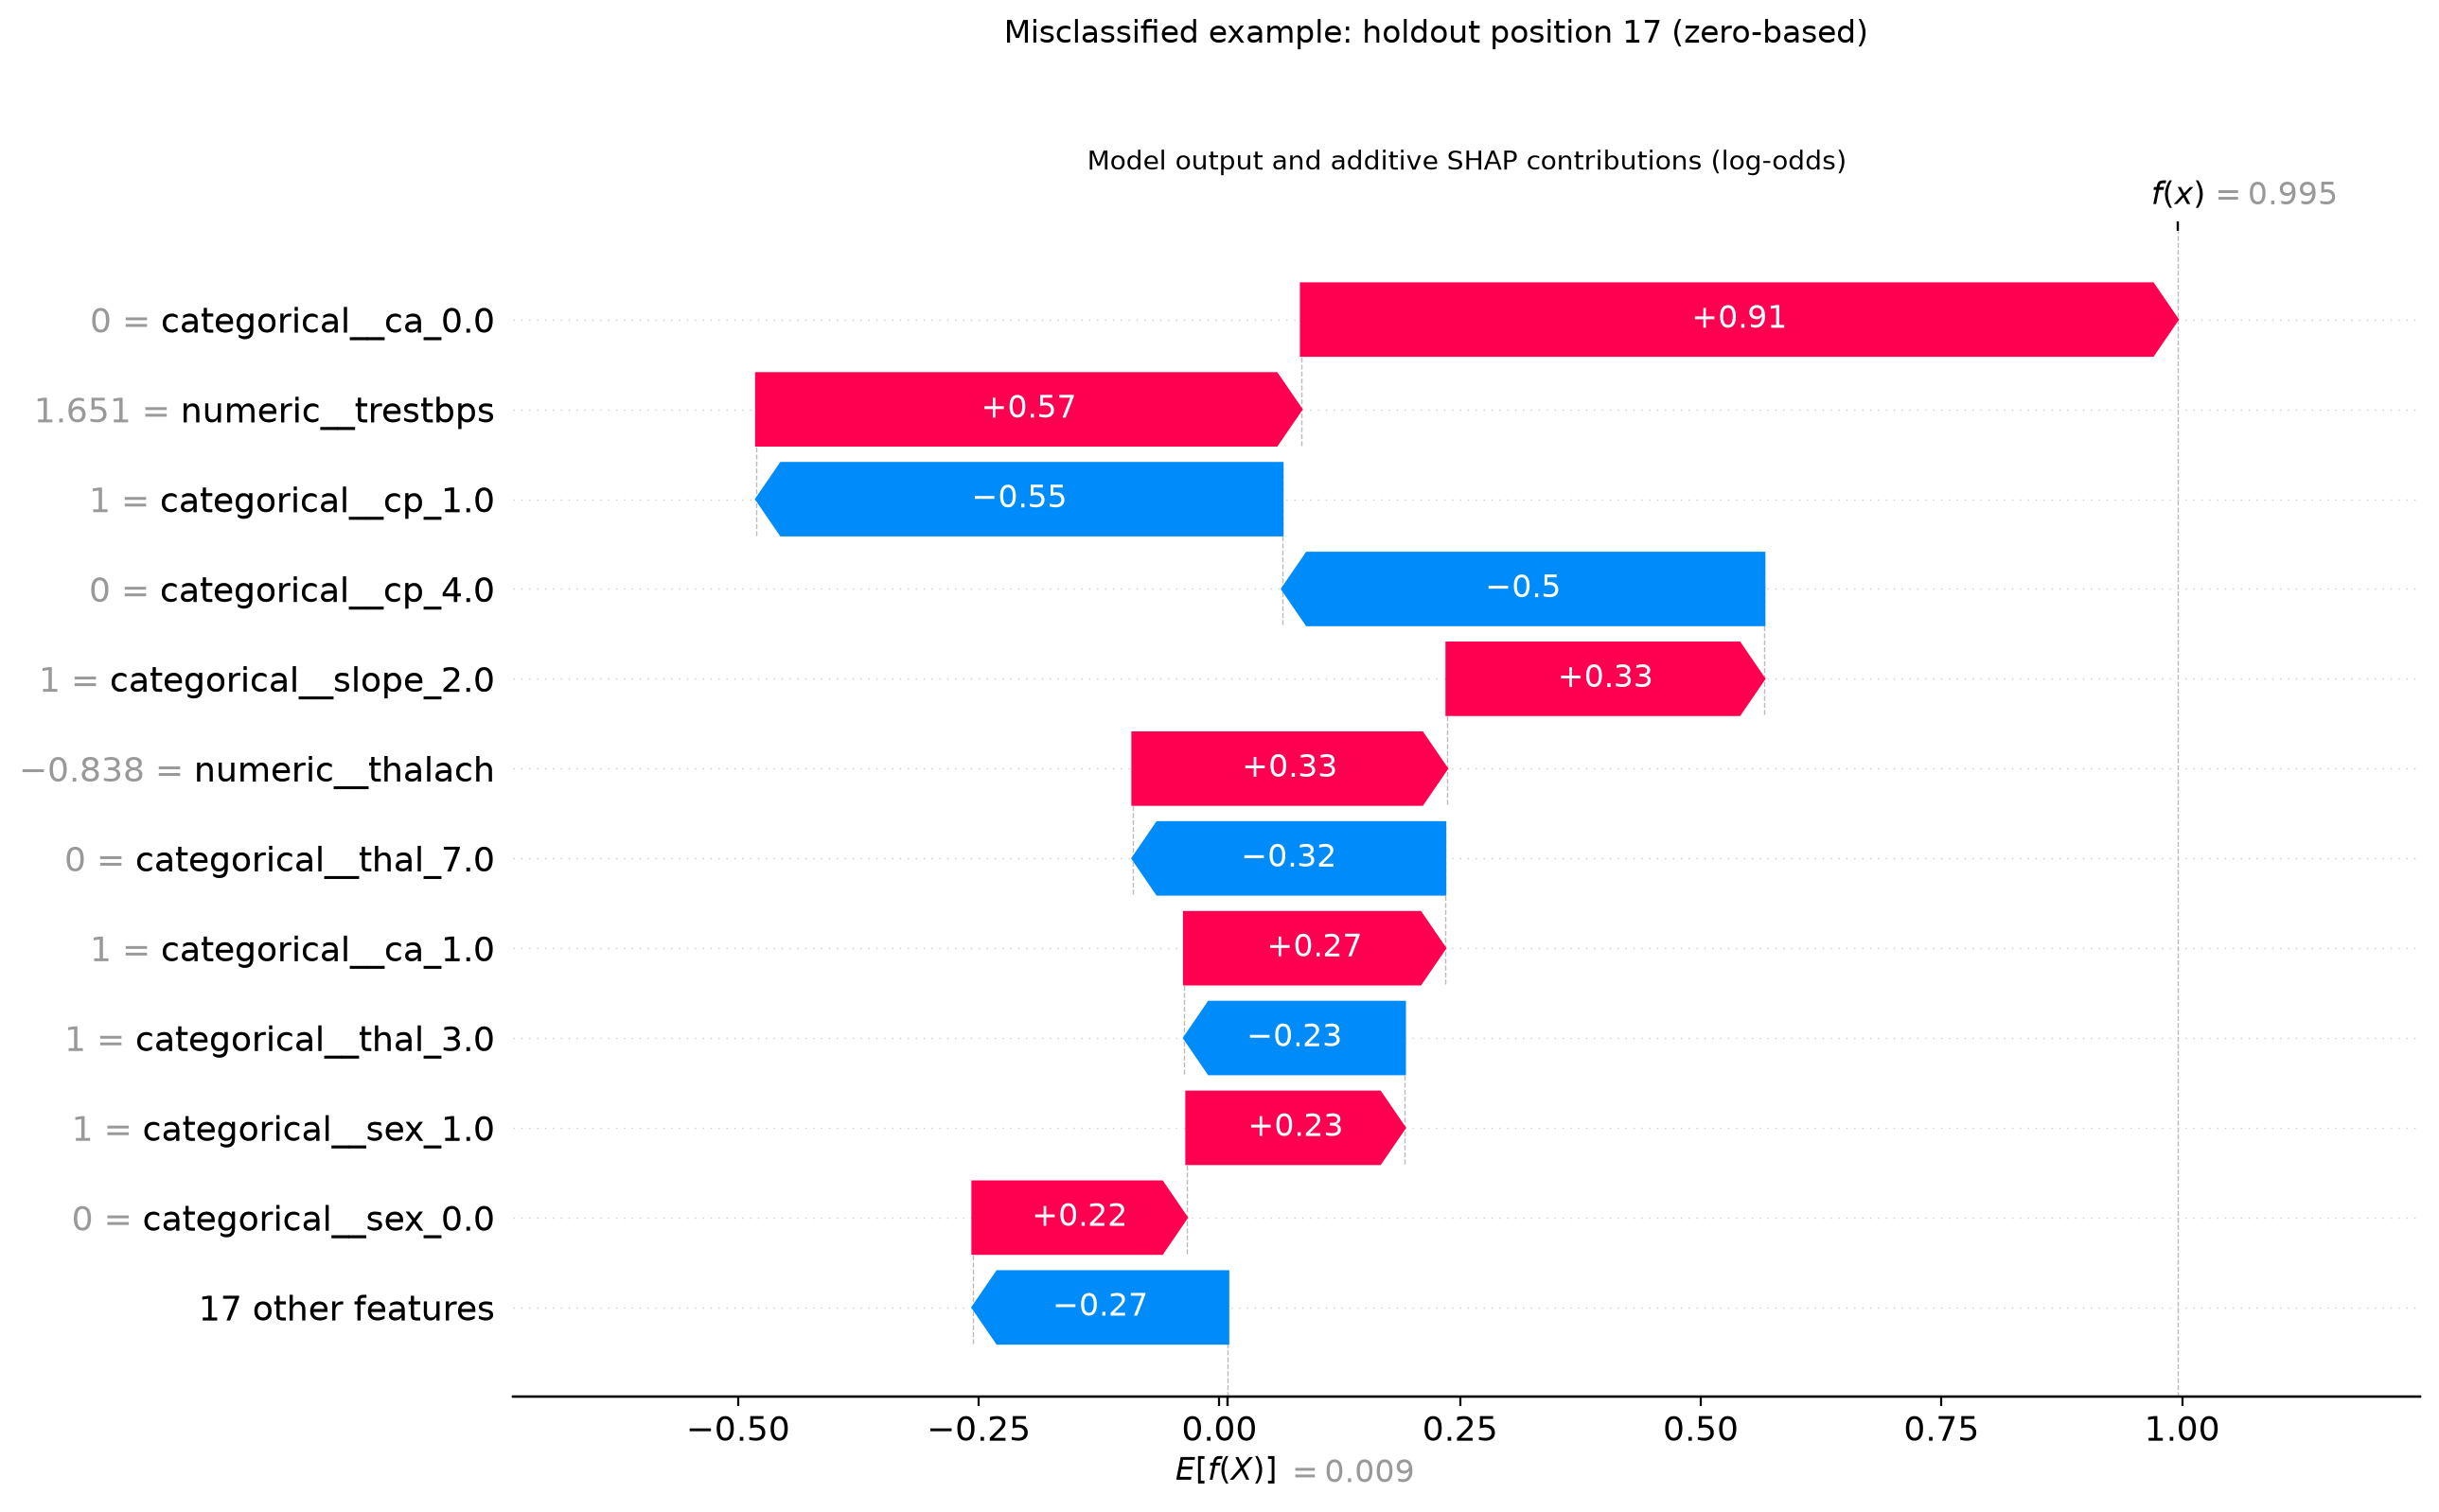

The largest upward contribution is **categorical__ca_0.0**; the largest downward contribution is **categorical__cp_1.0**. Their signs describe this model relative to its background, not medical causes.

In [11]:
display_example("misclassified")

## 13. Validate the mathematics and model preservation

For each transformed record z, the model's log-odds is
`b + sum(beta_j * z_j)`. The baseline is `b + sum(beta_j * mean_background_j)`.
Each interventional linear SHAP contribution is
`beta_j * (z_j - mean_background_j)`. Therefore baseline plus all contributions
reconstructs the decision value. The sigmoid is `1 / (1 + exp(-log_odds))`.
It converts the total to the model's positive-class score. **Do not add log-odds
contributions to a probability.** Sigmoid of the baseline is also not the
average background score, because sigmoid is nonlinear.

**Code explanation:** Validate reconstruction on all 61 records, including the
analytic linear formula and probability conversion. Tolerances are `1e-10`
for log-odds and contributions and `1e-12` for scores. Display maximum observed
errors and compare the model file's SHA-256 with its original value. Tiny
floating-point residuals demonstrate mathematical consistency, not clinical validity.

In [12]:
diagnostics = validate_reconstruction(engine, X_test, shap_values)
display(pd.Series(diagnostics, name="Maximum absolute error").to_frame())
reconstructed = shap_values.base_values + shap_values.values.sum(axis=1)
np.testing.assert_allclose(expit(reconstructed), pipeline.predict_proba(X_test)[:, 1], rtol=0, atol=1e-12)
assert sha256(artifact_path.read_bytes()).hexdigest() == artifact_before
print("All 61 explanations reconstruct model log-odds and scores within tolerance.")
print("Saved model artifact unchanged; no model or preprocessing fit was performed.")

,Maximum absolute error
max_log_odds_error,1.776357e-15
max_score_error,1.665335e-16
max_analytic_contribution_error,0.000000e+00


All 61 explanations reconstruct model log-odds and scores within tolerance.
Saved model artifact unchanged; no model or preprocessing fit was performed.


## 14. Interpretation and limitations

SHAP describes the model's learned associations relative to this background.
It does not estimate causal effects, clinical relevance, or a patient's true
disease risk. Importance is sample- and representation-dependent. Independence
masking ignores relationships between correlated clinical measurements and
mutual exclusivity of one-hot columns; allocation can differ under other choices.
Grouping magnitudes is not the same as net additive attribution or solving a
different coalition game over the original variables.

UCI Cleveland is small and historical. Earlier full-cohort EDA and limited
demographic coverage constrain conclusions. There is no independent external
validation or clinical probability calibration. Diagnostic features such as
`ca` and `thal` may be unavailable at an intended earlier decision time.
Public examples have no identifying fields, and JSON exports omit full raw
feature profiles. Never add private patient records to notebook outputs or Git.

A well-explained mistake remains a mistake. Do not infer treatment, disease
causation, clinical approval, or validated diagnostic performance from these plots.

## 15. Conclusion and next steps

We explained all 61 held-out observations using only training-background
information, ranked transformed and grouped features, inspected deterministic
present/absent/error examples, and verified the model-output reconstruction.
The saved model and previous phases remain unchanged.

Outputs: `reports/figures/explainability/` and
`reports/metrics/explainability.json`. Implementation and interpretation details
are documented in `docs/explainable_ai.md`. Run the complete test suite with
`python -m pytest -q`. CLI reproduction uses `python -m src.explainability`;
`--overwrite` regenerates only XAI outputs, never the fitted model.

Phase 4 ends here. Any FastAPI, frontend, database, or deployment work requires
approval for a later phase.